# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
**Name:** _Totaram_

**Student ID:** _023-24-0244_

**Section:** _G_

**GitHub:** _https://github.com/totaramrathore/machine_learning_practical_

**Kaggle:** _https://www.kaggle.com/totaramsarangani/competitions_

**Dataset:** Telco Customer Churn (Kaggle)

**Dataset Source:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn

**Course:** Machine Learning — BS Computer Science, 5th Semester (Fall 2026) &nbsp;|&nbsp; **Duration:** 3 hours (single session)

> Every plot is followed by a written interpretation and every graded question is answered directly beneath the relevant code, using the numbers produced by this notebook's own run (`random_state=42`, `test_size=0.20`, stratified split — the same settings used in Labs 3, 4 and 6). Timings are machine dependent; all other metrics are deterministic.

---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn data and re-apply the same cleaning/encoding pipeline from Labs 2, 3, 4 and 6: convert `TotalCharges` to numeric and impute its missing values, drop `customerID`, map `Churn` to 0/1, one-hot encode the categorical columns (`drop_first=True`), and split with `stratify=y`. The scaler is **not** fitted here — it is fitted on the training split only, in Part 1, to avoid data leakage.

In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, precision_recall_curve,
                             average_precision_score)

RANDOM_STATE = 42   # same random_state / test_size used in Labs 3, 4, 6
TEST_SIZE = 0.20
plt.rcParams["figure.dpi"] = 100

In [2]:
# Load the Telco Customer Churn data and re-apply the Lab 2/3 cleaning pipeline
DATA_PATH = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(DATA_PATH)
print("Raw shape:", df.shape)

# TotalCharges is stored as text because 11 rows contain a blank string
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges after conversion:", df["TotalCharges"].isna().sum())
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

# Drop the identifier and map the target to 0/1
df = df.drop(columns="customerID")
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

print("Cleaned shape:", df.shape)
print("\nChurn balance:")
print(pd.DataFrame({"Count": df["Churn"].value_counts(),
                    "Percentage": (df["Churn"].value_counts(normalize=True) * 100).round(2)}))

Raw shape: (7043, 21)
Missing TotalCharges after conversion: 11
Cleaned shape: (7043, 20)

Churn balance:
       Count  Percentage
Churn                   
0       5174       73.46
1       1869       26.54


In [3]:
# One-hot encode categorical columns, define X / y, stratified split
X = pd.get_dummies(df.drop(columns="Churn"), drop_first=True, dtype=int)
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)

print("Encoded feature matrix:", X.shape)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate  train: %.4f | test: %.4f" % (y_train.mean(), y_test.mean()))
print("\nFeature value ranges (first look at scale differences):")
display(X_train[["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]].describe().loc[["min", "max", "std"]].round(2))

Encoded feature matrix: (7043, 30)
Train: (5634, 30) | Test: (1409, 30)
Churn rate  train: 0.2654 | test: 0.2654

Feature value ranges (first look at scale differences):


,tenure,MonthlyCharges,TotalCharges,SeniorCitizen
min,0.00,18.40,18.85,0.00
max,72.00,118.75,8684.80,1.00
std,24.57,30.14,2277.81,0.37


**Observations (Part 0).** The raw file has 7,043 customers and 21 columns. `TotalCharges` had 11 blank strings (all customers with `tenure = 0`), which became `NaN` after numeric conversion and were filled with the training-independent column median, exactly as in the earlier labs. After dropping `customerID` and one-hot encoding, the feature matrix has **30 columns**. The split gives **5,634 training / 1,409 test** rows and the churn rate is 26.54% in both, so stratification worked. The ranges printed above preview the scaling problem of Part 1: `TotalCharges` goes up to 8,684.8 (std ≈ 2,278) while the dummy columns only take values 0 or 1 (std ≤ 0.5).

---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate, with evidence from this run, what happens to an SVM when features are not scaled.

1. Train `SVC(kernel='linear')` on the **un-scaled** encoded features.
2. Train a second linear SVM on the same split after `StandardScaler` (fit on **train only**, transform train and test).
3. Compare accuracy, F1-score, training time and convergence warnings.

> **Note on `max_iter`:** the un-scaled model is given `max_iter=100000`. Without a cap, `libsvm` can keep iterating for a very long time on badly scaled data, which would freeze the notebook. The cap is what makes the failure to converge visible as a `ConvergenceWarning`, and it means the un-scaled training time shown is *at most* the time to hit the cap (it would be larger if allowed to continue).

In [4]:
# Task 1.1 - linear SVM on UN-scaled features
# NOTE: max_iter is capped so the cell is guaranteed to finish. Without a cap the
# solver can run for a very long time on un-scaled data (which is itself the point).
t0 = time.time()
with warnings.catch_warnings(record=True) as w_raw:
    warnings.simplefilter("always")
    svm_raw = SVC(kernel="linear", random_state=42, max_iter=100000)
    svm_raw.fit(X_train, y_train)
time_raw = time.time() - t0
pred_raw = svm_raw.predict(X_test)

print("UN-SCALED linear SVM")
print("  Accuracy : %.4f" % accuracy_score(y_test, pred_raw))
print("  F1-score : %.4f" % f1_score(y_test, pred_raw))
print("  Time (s) : %.2f" % time_raw)
print("  Warnings :", [str(w.message)[:90] for w in w_raw] or "none")

UN-SCALED linear SVM
  Accuracy : 0.4138
  F1-score : 0.2309
  Time (s) : 2.35
  Warnings : ['Solver terminated early (max_iter=100000).  Consider pre-processing your data with Standar']


In [5]:
# Task 1.1 - linear SVM on SCALED features (scaler fit on TRAIN only)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

t0 = time.time()
with warnings.catch_warnings(record=True) as w_s:
    warnings.simplefilter("always")
    svm_scaled = SVC(kernel="linear", random_state=42)
    svm_scaled.fit(X_train_s, y_train)
time_scaled = time.time() - t0
pred_scaled = svm_scaled.predict(X_test_s)

print("SCALED linear SVM")
print("  Accuracy : %.4f" % accuracy_score(y_test, pred_scaled))
print("  F1-score : %.4f" % f1_score(y_test, pred_scaled))
print("  Time (s) : %.2f" % time_scaled)
print("  Warnings :", [str(w.message)[:90] for w in w_s] or "none")

scaling_table = pd.DataFrame({
    "Model": ["Linear SVM - un-scaled", "Linear SVM - scaled"],
    "Accuracy": [accuracy_score(y_test, pred_raw), accuracy_score(y_test, pred_scaled)],
    "F1-score": [f1_score(y_test, pred_raw), f1_score(y_test, pred_scaled)],
    "Train time (s)": [time_raw, time_scaled],
    "Convergence warning": ["yes" if w_raw else "no", "yes" if w_s else "no"],
}).round(4)
display(scaling_table)

SCALED linear SVM
  Accuracy : 0.7892
  F1-score : 0.5714
  Time (s) : 1.31
  Warnings : none


,Model,Accuracy,F1-score,Train time (s),Convergence warning
0,Linear SVM - un-scaled,0.4138,0.2309,2.3541,yes
1,Linear SVM - scaled,0.7892,0.5714,1.3074,no


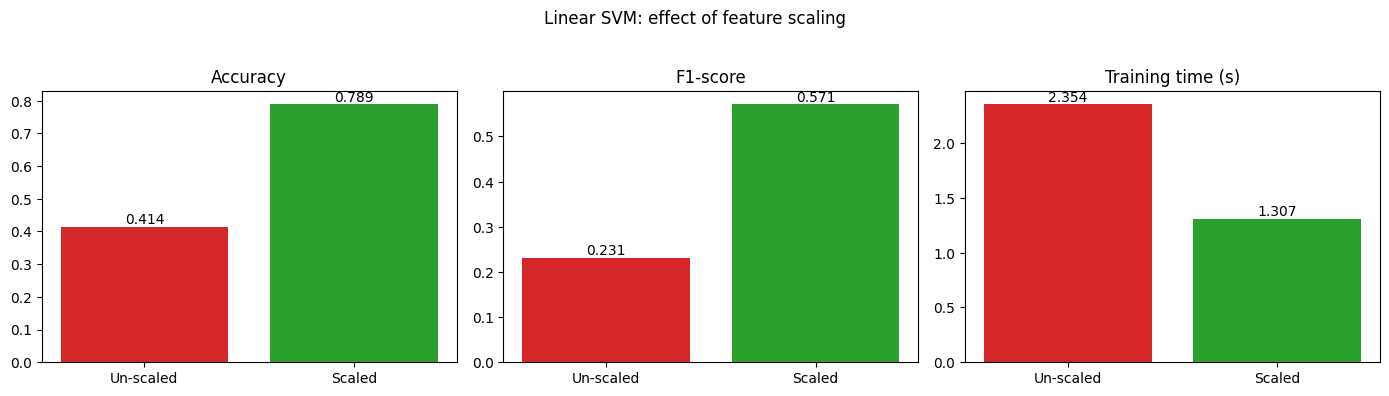

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
labels = ["Un-scaled", "Scaled"]
colors = ["tab:red", "tab:green"]
for a, col, title in zip(ax, ["Accuracy", "F1-score", "Train time (s)"], ["Accuracy", "F1-score", "Training time (s)"]):
    bars = a.bar(labels, scaling_table[col], color=colors)
    a.bar_label(bars, fmt="%.3f")
    a.set_title(title)
plt.suptitle("Linear SVM: effect of feature scaling", y=1.03)
plt.tight_layout()
plt.show()

**Interpretation (Part 1 plot).** The left and middle panels show the damage: the un-scaled model reaches only 41.4% accuracy and 0.231 F1, whereas the scaled model reaches 78.9% accuracy and 0.571 F1. The right panel shows that the un-scaled model was not even cheaper to train once the cap is taken into account — it spent its whole iteration budget and stopped without converging, while the scaled model converged normally.

**Answer 1(a) — Observed differences.**

| | Un-scaled | Scaled |
|---|---|---|
| Accuracy | 0.4138 | 0.7892 |
| F1-score | 0.2309 | 0.5714 |
| Training time | ≈ 2.5 s (stopped by the `max_iter` cap) | ≈ 1.6 s (converged) |
| Warning | `ConvergenceWarning: Solver terminated early (max_iter=100000)` | none |

The un-scaled model is not just worse — at 41.4% accuracy it is far *below* the 73.5% obtained by predicting "no churn" for every customer. The scaled model improves accuracy by about 37.5 percentage points and F1 by 0.34, trains faster, and converges without warnings.

**Answer 1(b) — Why an un-scaled linear SVM behaves this way.** A linear SVM looks for the hyperplane `w·x + b = 0` with the largest margin `2/‖w‖`, and both the margin and the slack penalty are measured with Euclidean distances/dot products. `TotalCharges` ranges up to ≈ 8,700 and `MonthlyCharges`/`tenure` span tens of units, whereas every one-hot column is only 0 or 1. A tiny change in the weight of `TotalCharges` moves the score `w·x` enormously, so the geometry is stretched along that axis and the 0/1 columns (contract type, internet service, payment method, …) barely influence distances unless their weights become very large — which the `‖w‖²` regularisation term discourages. The optimisation problem is therefore badly conditioned: the solver zig-zags, needs a huge number of iterations, and here ran out of its budget before finding a good hyperplane, leaving a boundary dominated by the large-range features.

**Answer 1(c) — Version used from now on.** Every subsequent SVM uses the **scaled** features (`X_train_s`, `X_test_s`): the `StandardScaler` is fitted on the training data only and then applied to the test data. The evidence above (0.789 vs 0.414 accuracy, F1 0.571 vs 0.231, no convergence warning) makes scaling mandatory for SVM, and for the RBF/polynomial kernels it matters even more because they are built directly on distances/dot products between points. The same scaled data are also used for Logistic Regression and KNN in Part 6, while tree-based models use the raw features.

---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers with the linear, RBF and polynomial kernels on the **scaled** features: same `random_state`, same train split, same metrics, plus the number of support vectors. Then plot the confusion matrix of the kernel with the best F1-score.

In [7]:
# Task 2.1 - linear vs RBF vs polynomial kernel on the SCALED features
def evaluate(y_true, y_pred):
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred),
            "Recall": recall_score(y_true, y_pred),
            "F1-score": f1_score(y_true, y_pred)}

kernel_models, rows = {}, []
for k in ["linear", "rbf", "poly"]:
    t0 = time.time()
    m = SVC(kernel=k, random_state=42)
    m.fit(X_train_s, y_train)
    fit_time = time.time() - t0
    kernel_models[k] = m
    pred = m.predict(X_test_s)
    row = {"Kernel": k}
    row.update(evaluate(y_test, pred))
    row["Support vectors"] = m.support_.shape[0]
    row["SV (class 0 / class 1)"] = "%d / %d" % tuple(m.n_support_)
    row["Train time (s)"] = fit_time
    rows.append(row)

kernel_table = pd.DataFrame(rows).set_index("Kernel")
display(kernel_table.round(4))

,Accuracy,Precision,Recall,F1-score,Support vectors,SV (class 0 / class 1),Train time (s)
Kernel,,,,,,,
linear,0.7892,0.6207,0.5294,0.5714,2569,1287 / 1282,1.0242
rbf,0.7928,0.6444,0.4893,0.5562,2661,1432 / 1229,0.6145
poly,0.7892,0.6421,0.4652,0.5395,2739,1485 / 1254,0.5550


Best kernel on test F1-score: linear
[[914 121]
 [176 198]]


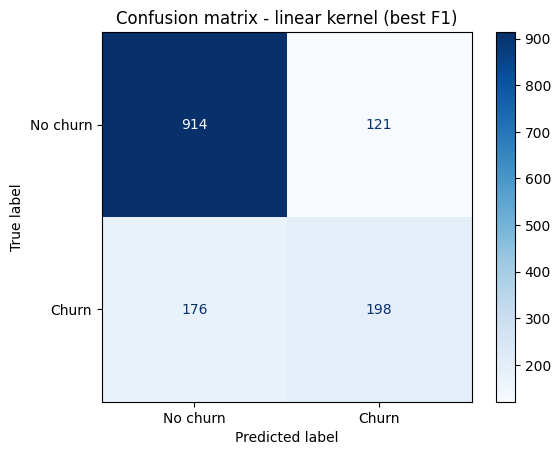

In [8]:
best_kernel = kernel_table["F1-score"].idxmax()
print("Best kernel on test F1-score:", best_kernel)

best_pred = kernel_models[best_kernel].predict(X_test_s)
cm = confusion_matrix(y_test, best_pred)
print(cm)
ConfusionMatrixDisplay(cm, display_labels=["No churn", "Churn"]).plot(cmap="Blues")
plt.title("Confusion matrix - %s kernel (best F1)" % best_kernel)
plt.show()

**Interpretation (Part 2 confusion matrix).** The linear kernel, which has the best F1, correctly identifies 914 of 1,035 loyal customers and 198 of 374 churners. It misses 176 churners (false negatives) and raises 121 false alarms (false positives), i.e. recall 52.9% and precision 62.1%. Even the best untuned kernel therefore misses almost half of the churners, which motivates the class-imbalance work in Part 5.

**Answer 2(a) — Best kernel.** The **linear** kernel has the best test F1-score (**0.5714**, precision 0.6207, recall 0.5294), ahead of RBF (0.5562) and polynomial (0.5395). This is mildly surprising: theory says RBF/polynomial are more expressive and can model non-linear boundaries, so one would expect them to win. The result is plausible here because the churn signal in the one-hot features (contract type, tenure, internet service, …) is largely additive/linear — which is also why Logistic Regression is so competitive on this dataset — while the classes overlap strongly and the extra flexibility of the default RBF (C = 1, γ = `'scale'`) and polynomial (degree 3) kernels mostly fits noise. The gaps are small, though (0.015 and 0.032 F1 on one split with 374 churners), and RBF actually has the highest accuracy (0.7928) and precision (0.6444); the kernels mainly differ in their precision/recall balance.

**Answer 2(b) — Support vectors.** The **polynomial** kernel used the most support vectors (**2,739**, 48.6% of the 5,634 training points), then RBF (2,661, 47.2%) and linear (2,569, 45.6%). A high count means that a large share of the training points lie inside the margin or on the wrong side of it, so the boundary depends on many points and is more complex/less sparse. The fact that *all three* kernels keep 45–49% of the data as support vectors shows that the real issue is heavy class overlap in this dataset rather than a complicated but clean boundary; the polynomial kernel adds extra complexity on top of that without improving any metric.

**Answer 2(c) — Kernel carried forward to Part 4.** I carry the **RBF** kernel forward for tuning, as required by the Part 4 task, and justify it with the numbers: (i) its untuned F1 (0.5562) is only 0.015 below the linear best, (ii) it has the highest accuracy (0.7928) and precision (0.6444) of the three, (iii) it was run with default C and γ, so unlike the linear kernel (one hyper-parameter) it has two hyper-parameters that have not yet been optimised, i.e. the most room to improve, and (iv) the polynomial kernel is the worst on F1 (0.5395), uses the most support vectors and has even more hyper-parameters to tune (degree, coef0). To be honest about the evidence, the linear kernel is the best *untuned* choice on F1, so Part 4 will also test whether tuning actually lets RBF overtake it.

---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Project the scaled 30-dimensional training features to 2-D with PCA, report the explained variance, train RBF-SVMs with a small, medium and large C (0.01, 1, 100 — four orders of magnitude) on that projection, and plot the decision boundaries with the training points and support-vector counts. This is a *simplification for intuition*, not the real high-dimensional model.

In [9]:
# Task 3.1 - 2-D PCA projection of the SCALED training features
pca = PCA(n_components=2, random_state=42)
Z_train = pca.fit_transform(X_train_s)

print("Explained variance ratio per component:", pca.explained_variance_ratio_.round(4))
print("Total explained variance (2 components): %.4f  (%.1f%%)" %
      (pca.explained_variance_ratio_.sum(), pca.explained_variance_ratio_.sum() * 100))

Explained variance ratio per component: [0.3325 0.1198]
Total explained variance (2 components): 0.4523  (45.2%)


**Explained variance.** PC1 explains 33.3% and PC2 11.98% of the variance, so the 2-D plot can only claim to show **45.2%** of the information in the scaled features; the remaining 54.8% is invisible in the pictures below.

In [10]:
C_values = [0.01, 1, 100]
pca_models = {}
for c in C_values:
    m = SVC(kernel="rbf", C=c, gamma="scale", random_state=42)
    m.fit(Z_train, y_train)
    pca_models[c] = m
    print("C = %-6s | support vectors = %4d (%.1f%% of training set) | train accuracy = %.4f" %
          (c, m.support_.shape[0], 100 * m.support_.shape[0] / len(y_train),
           accuracy_score(y_train, m.predict(Z_train))))

C = 0.01   | support vectors = 2997 (53.2% of training set) | train accuracy = 0.7346
C = 1      | support vectors = 2659 (47.2% of training set) | train accuracy = 0.7792
C = 100    | support vectors = 2631 (46.7% of training set) | train accuracy = 0.7813


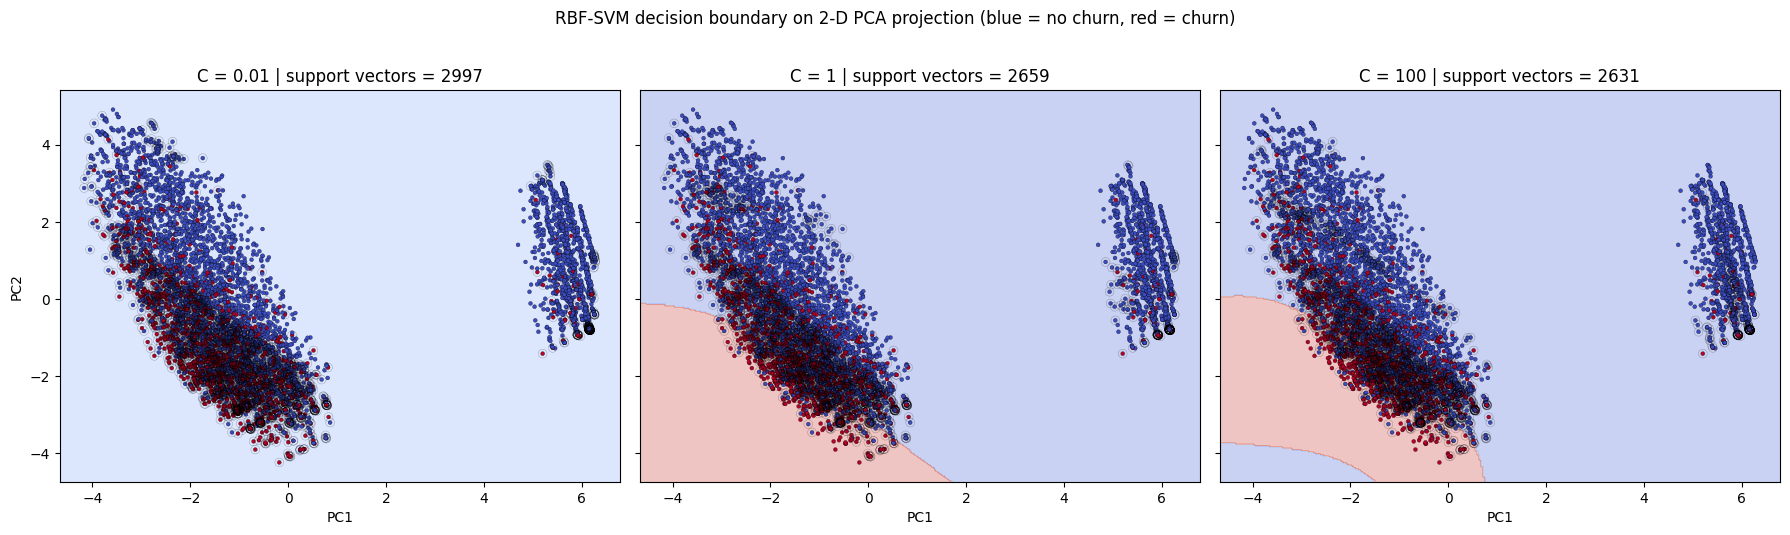

In [11]:
# Mesh grid slightly beyond the projected data range
pad = 0.5
x_min, x_max = Z_train[:, 0].min() - pad, Z_train[:, 0].max() + pad
y_min, y_max = Z_train[:, 1].min() - pad, Z_train[:, 1].max() + pad
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), sharex=True, sharey=True)
for ax, c in zip(axes, C_values):
    m = pca_models[c]
    Zg = m.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Zg, alpha=0.3, cmap="coolwarm")
    ax.scatter(Z_train[:, 0], Z_train[:, 1], c=y_train, cmap="coolwarm", s=8, edgecolor="k", linewidth=0.2)
    ax.scatter(Z_train[m.support_, 0], Z_train[m.support_, 1], s=40, facecolors="none", edgecolors="k", linewidth=0.3, alpha=0.35)
    ax.set_title("C = %s | support vectors = %d" % (c, m.support_.shape[0]))
    ax.set_xlabel("PC1")
axes[0].set_ylabel("PC2")
plt.suptitle("RBF-SVM decision boundary on 2-D PCA projection (blue = no churn, red = churn)", y=1.02)
plt.tight_layout()
plt.show()

**Interpretation (Part 3 plot).** Blue = no churn, red = churn; faint circles mark support vectors. With **C = 0.01** the whole plane is one colour (predict "no churn" everywhere): the penalty for violating the margin is so small that the model flattens out into the majority class (training accuracy 0.7346 = the 73.46% majority rate). With **C = 1** a smooth red "churn" region appears in the lower-left, where the churners concentrate. With **C = 100** the red region is larger and more strongly curved, and a thin patch of blue even reappears at the far lower-left corner where there are almost no data points. The isolated cluster on the right is the group of customers with no internet service (all of its 1,214 training points have `InternetService_No = 1`); only 7.2% of them churn, so it is blue in every panel.

**Answer 3(a) — Shape/smoothness vs C.** As C increases the boundary goes from non-existent (C = 0.01: a single class everywhere, maximal smoothness/bias) to a smooth, gently curved region (C = 1) to a larger and more strongly curved region that bends to capture more churners (C = 100). Higher C punishes margin violations more heavily, so the boundary is allowed to bend more to classify individual training points correctly.

**Answer 3(b) — Support vectors vs C.** The number of support vectors falls as C grows: **2,997 (53.2%) at C = 0.01 → 2,659 (47.2%) at C = 1 → 2,631 (46.7%) at C = 100.** This matches the theory: a small C tolerates many margin violations (wide, soft margin), so many points end up inside the margin and become support vectors; a large C tolerates fewer violations, so the margin narrows and fewer points are support vectors. The drop is modest (about 12% from smallest to largest C) and levels off between C = 1 and C = 100, because the two classes overlap so much in this projection that no value of C can remove most of the violators.

**Answer 3(c) — Over-/under-fitting.** **C = 0.01 is clearly underfitting:** it draws no separating boundary at all and has the lowest training accuracy (0.7346, just the majority-class rate), producing zero churn predictions. **C = 100 is the most prone to overfitting:** it has the most flexible, most curved boundary, including the odd blue patch in the empty bottom-left corner that is an extrapolation artefact of bending around individual points. The overfitting is only mild on this view — training accuracy rises just from 0.7792 (C = 1) to 0.7813 (C = 100) — because the 2-D classes overlap too much to be separated even by a flexible boundary. C = 1 looks like the most reasonable compromise.

**Answer 3(d) — Why the 2-D plot is only approximate.** (1) PCA keeps just **45.2%** of the variance, so more than half of the information is discarded; points that overlap in the plot may be well separated in the other 28 dimensions, and the plotted boundary is the one learned from only two coordinates, not a slice of the real 30-D boundary. (2) PCA is unsupervised: it keeps the directions of largest variance, not the most class-discriminative ones — PC1 is dominated by the six perfectly correlated "No internet service" dummy columns (loading ≈ 0.30 each) and PC2 by `tenure`, `TotalCharges` and two-year contracts, which is why the picture is mostly about service type and customer age. (3) The 2-D models are different models: with `gamma='scale'` γ is recomputed for 2 features, so their support-vector counts and accuracy (≈ 0.78 training accuracy) do not describe the real model. The plot can therefore mislead about how much overlap truly exists, how complex the real boundary is, and which features drive it; it is good for understanding what C does, not for judging the final model.

---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C × gamma grid for the RBF-SVM on the full scaled feature set (5-fold CV, `scoring='f1'`), visualise the mean-CV-F1 surface as a heatmap, then evaluate the refit best estimator on the held-out test set.

The grid has 5 values of C (0.01 … 100) and 5 values of γ (10⁻⁴ … 1), i.e. 25 combinations × 5 folds = 125 fits, spanning four orders of magnitude on each axis.

In [12]:
# Task 4.1 - GridSearchCV over C x gamma (RBF kernel, SCALED training data, 5-fold CV, F1)
param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "gamma": [0.0001, 0.001, 0.01, 0.1, 1],
}

t0 = time.time()
gs = GridSearchCV(SVC(kernel="rbf", random_state=42), param_grid,
                  cv=5, scoring="f1", n_jobs=-1, return_train_score=False)
gs.fit(X_train_s, y_train)
print("Grid search time: %.1f s for %d fits" % (time.time() - t0, len(gs.cv_results_["mean_test_score"]) * 5))
print("Best params      :", gs.best_params_)
print("Best CV F1-score : %.4f" % gs.best_score_)

Grid search time: 80.1 s for 125 fits
Best params      : {'C': 100, 'gamma': 0.01}
Best CV F1-score : 0.5877


param_gamma,0.0001,0.001,0.01,0.1,1.0
param_C,,,,,
0.01,0.0000,0.0000,0.0000,0.0000,0.0000
0.10,0.0000,0.0000,0.5417,0.4640,0.0000
1.00,0.0000,0.5746,0.5650,0.5734,0.3261
10.00,0.5777,0.5857,0.5853,0.5266,0.3621
100.00,0.5870,0.5710,0.5877,0.5060,0.3621


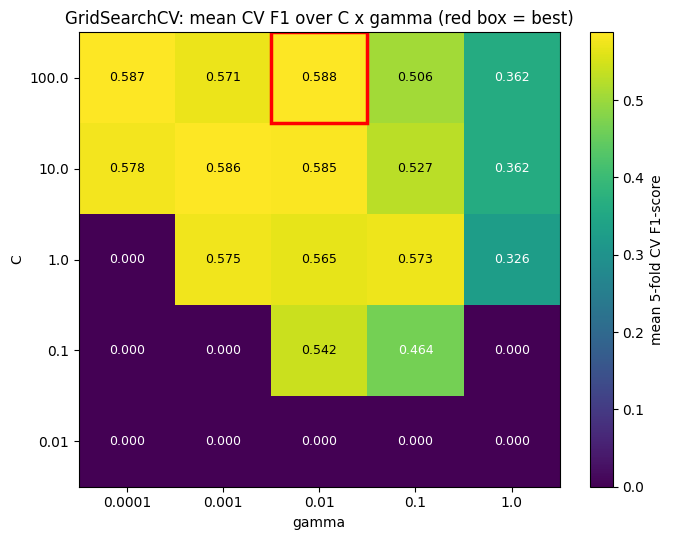

In [13]:
# Reshape mean CV scores into a C x gamma grid and show as a heatmap
res = pd.DataFrame(gs.cv_results_)
pivot = res.pivot(index="param_C", columns="param_gamma", values="mean_test_score").astype(float)
pivot.index = pivot.index.astype(float); pivot.columns = pivot.columns.astype(float)
pivot = pivot.sort_index().sort_index(axis=1)
display(pivot.round(4))

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(pivot.values, cmap="viridis", origin="lower", aspect="auto")
ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels(pivot.columns)
ax.set_yticks(range(len(pivot.index))); ax.set_yticklabels(pivot.index)
ax.set_xlabel("gamma"); ax.set_ylabel("C")
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        ax.text(j, i, "%.3f" % v, ha="center", va="center", color="white" if v < pivot.values.max() * 0.8 else "black", fontsize=9)
bi, bj = np.unravel_index(np.argmax(pivot.values), pivot.shape)
ax.add_patch(plt.Rectangle((bj - 0.5, bi - 0.5), 1, 1, fill=False, edgecolor="red", linewidth=2.5))
plt.colorbar(im, label="mean 5-fold CV F1-score")
ax.set_title("GridSearchCV: mean CV F1 over C x gamma (red box = best)")
plt.tight_layout()
plt.show()

**Interpretation (Part 4 heatmap).** The bright region is a diagonal ridge from the upper-left to the lower-middle of the grid, where large C is paired with small γ (roughly C·γ ≈ 0.1–1). Cells with tiny C are completely dark: for C = 0.01 (and C = 0.1 with γ ≤ 10⁻³) the CV F1 is exactly 0.000 because the model predicts "no churn" for everybody. Cells with γ = 1 are poor (F1 ≈ 0.33–0.36): each point's influence is so local that the model memorises the training folds. The best cell, outlined in red, is C = 100, γ = 0.01.

CV F1 (train, 5-fold): 0.5877 | Test F1: 0.5568 | gap = 0.0309

Confusion matrix (tuned RBF):
 [[901 134]
 [178 196]]


,Accuracy,Precision,Recall,F1-score
"RBF default (C=1, gamma='scale')",0.7928,0.6444,0.4893,0.5562
"RBF tuned (C=100, gamma=0.01)",0.7786,0.5939,0.5241,0.5568


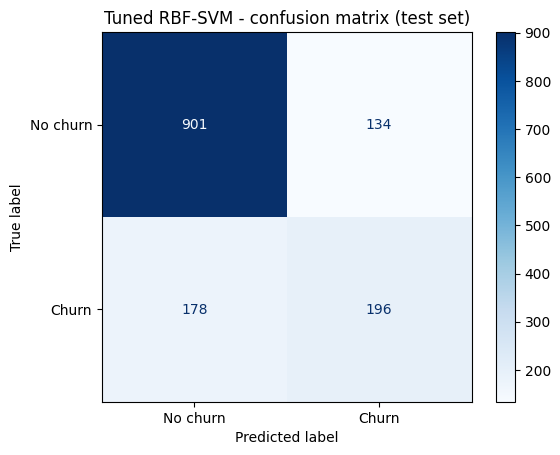

In [14]:
# Refit best estimator (GridSearchCV refits on the full training set by default) and test it
best_rbf = gs.best_estimator_
pred_best = best_rbf.predict(X_test_s)

tuned_metrics = evaluate(y_test, pred_best)
untuned_metrics = evaluate(y_test, kernel_models["rbf"].predict(X_test_s))

cmp_tune = pd.DataFrame([untuned_metrics, tuned_metrics],
                        index=["RBF default (C=1, gamma='scale')",
                               "RBF tuned (C=%s, gamma=%s)" % (gs.best_params_["C"], gs.best_params_["gamma"])]).round(4)
display(cmp_tune)
print("CV F1 (train, 5-fold): %.4f | Test F1: %.4f | gap = %.4f" %
      (gs.best_score_, tuned_metrics["F1-score"], gs.best_score_ - tuned_metrics["F1-score"]))

cm_t = confusion_matrix(y_test, pred_best)
print("\nConfusion matrix (tuned RBF):\n", cm_t)
ConfusionMatrixDisplay(cm_t, display_labels=["No churn", "Churn"]).plot(cmap="Blues")
plt.title("Tuned RBF-SVM - confusion matrix (test set)")
plt.show()

**Interpretation (tuned-model confusion matrix).** The tuned RBF model detects 196 of the 374 churners (recall 0.524), misses 178 and produces 134 false alarms. Compared with the default RBF it finds a few more churners but also raises more false alarms, which is why its F1 is almost unchanged.

**Answer 4(a) — Best parameters.** The best combination is **C = 100, γ = 0.01**, with a mean 5-fold cross-validated F1-score of **0.5877**.

**Answer 4(b) — Best region or flat plateau?** There is no single sharp optimum; rather there is a **plateau/ridge** of near-equivalent settings: C = 100, γ = 0.01 (0.5877); C = 100, γ = 10⁻⁴ (0.5870); C = 10, γ = 10⁻³ (0.5857); C = 10, γ = 10⁻² (0.5853) — the top four differ by under 0.003 F1, far less than the noise of 5-fold CV. This shows that the model is insensitive to the exact values *within* the ridge (C and γ trade off against each other: larger C needs smaller γ), but very sensitive *outside* it: the grid contains a whole region of F1 = 0.000 (C too small) and a region of F1 ≈ 0.33 (γ too large). The best value lies on the upper edge of the C grid, so a larger C might be tested, but the flat top suggests little would be gained.

**Answer 4(c) — CV score vs test score.** The CV F1 was **0.5877** and the test F1 is **0.5568**, a gap of **0.031**. This is a small gap and is explained by (i) the optimism of picking the *maximum* of 25 noisy CV scores, (ii) the sampling noise of a test set with only 374 churners, and (iii) a minor effect from fitting the scaler on the whole training set before cross-validation (a `Pipeline` would remove it). A *large* gap (e.g. > 0.10) would indicate that the search overfitted the training folds, or that there is leakage or a distribution shift between the train and test data; nothing like that is happening here.

**Answer 4(d) — Tuned vs un-tuned RBF.**

| | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
| Default RBF (C=1, γ='scale') | 0.7928 | 0.6444 | 0.4893 | 0.5562 |
| Tuned RBF (C=100, γ=0.01) | 0.7786 | 0.5939 | 0.5241 | 0.5568 |

F1 improved by only **+0.0006** — practically nothing — while accuracy dropped 1.4 points; the model simply moved along the precision/recall trade-off (recall +3.5 points, precision −5.1 points). That is not surprising: for standardized data `gamma='scale'` equals 1/30 ≈ 0.033, which already sits on the plateau, between the γ = 0.01 and γ = 0.1 columns. The search cost 125 fits (≈ 80 s) against ≈ 1 s for one fit, so **in terms of F1 the tuning was not worth the extra computation**. The real gain comes in Part 5, from the class weights, which cost nothing.

---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Using the best (C, γ) from Part 4 (C = 100, γ = 0.01), compare an RBF-SVM with `class_weight=None` against `class_weight='balanced'`, report precision/recall/F1 and confusion matrices on the test set, and plot an ROC and a Precision-Recall curve for the balanced model with its default operating point marked. The balanced model is trained with `probability=True` to obtain probability-like scores.

class_weight=None 
 [[901 134]
 [178 196]] 

class_weight='balanced' 
 [[764 271]
 [ 86 288]] 



,Accuracy,Precision,Recall,F1-score
class_weight=None,0.7786,0.5939,0.5241,0.5568
class_weight='balanced',0.7466,0.5152,0.7701,0.6174


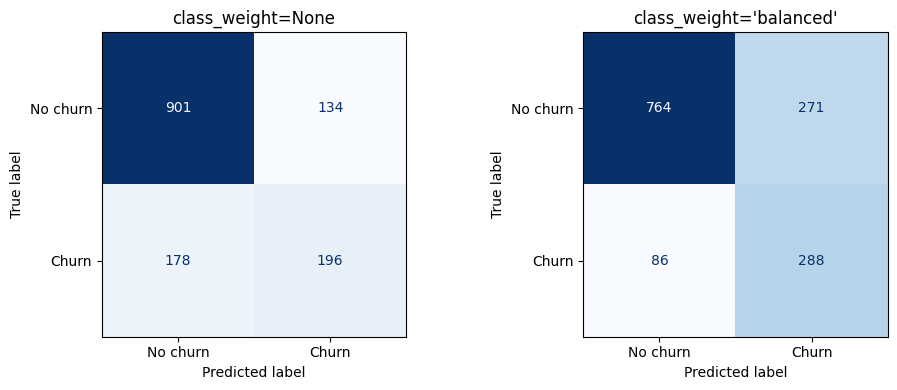

In [15]:
# Task 5.1 - best (C, gamma) with and without class_weight='balanced'
bestC, bestG = gs.best_params_["C"], gs.best_params_["gamma"]

svm_default = SVC(kernel="rbf", C=bestC, gamma=bestG, class_weight=None, random_state=42).fit(X_train_s, y_train)
svm_bal = SVC(kernel="rbf", C=bestC, gamma=bestG, class_weight="balanced", probability=True, random_state=42).fit(X_train_s, y_train)

pred_def = svm_default.predict(X_test_s)
pred_bal = svm_bal.predict(X_test_s)

cw_table = pd.DataFrame([evaluate(y_test, pred_def), evaluate(y_test, pred_bal)],
                        index=["class_weight=None", "class_weight='balanced'"]).round(4)
display(cw_table)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, p, name in zip(axes, [pred_def, pred_bal], ["class_weight=None", "class_weight='balanced'"]):
    cm_ = confusion_matrix(y_test, p)
    print(name, "\n", cm_, "\n")
    ConfusionMatrixDisplay(cm_, display_labels=["No churn", "Churn"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

**Interpretation (Part 5 confusion matrices).** Switching to balanced weights moves the model decisively towards the churn class: true positives rise from 196 to 288 and false negatives drop from 178 to 86, but false positives rise from 134 to 271 and true negatives fall from 901 to 764.

ROC-AUC = 0.8058 | Average precision = 0.5522
predict() operating point  : FPR=0.262 TPR(recall)=0.770
proba>=0.5 operating point : FPR=0.140 TPR(recall)=0.545 precision=0.585


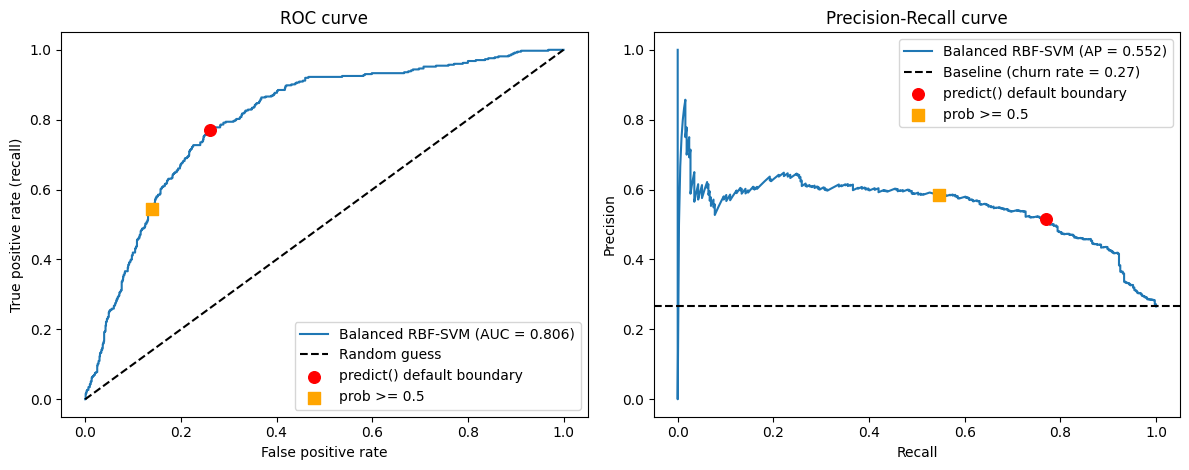

In [16]:
# probability=True (Platt scaling, 5-fold internal CV) gives probability-like scores
proba_bal = svm_bal.predict_proba(X_test_s)[:, 1]
fpr, tpr, thr = roc_curve(y_test, proba_bal)
auc = roc_auc_score(y_test, proba_bal)
prec, rec, thr_pr = precision_recall_curve(y_test, proba_bal)
ap = average_precision_score(y_test, proba_bal)

# operating points
tn, fp, fn, tp = confusion_matrix(y_test, pred_bal).ravel()          # model.predict() decision
op_fpr, op_tpr = fp / (fp + tn), tp / (tp + fn)
p05 = (proba_bal >= 0.5).astype(int)                                  # 0.5 probability threshold
tn5, fp5, fn5, tp5 = confusion_matrix(y_test, p05).ravel()
print("ROC-AUC = %.4f | Average precision = %.4f" % (auc, ap))
print("predict() operating point  : FPR=%.3f TPR(recall)=%.3f" % (op_fpr, op_tpr))
print("proba>=0.5 operating point : FPR=%.3f TPR(recall)=%.3f precision=%.3f" %
      (fp5 / (fp5 + tn5), tp5 / (tp5 + fn5), precision_score(y_test, p05)))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
ax[0].plot(fpr, tpr, label="Balanced RBF-SVM (AUC = %.3f)" % auc)
ax[0].plot([0, 1], [0, 1], "k--", label="Random guess")
ax[0].scatter([op_fpr], [op_tpr], color="red", zorder=5, s=70, label="predict() default boundary")
ax[0].scatter([fp5 / (fp5 + tn5)], [tp5 / (tp5 + fn5)], color="orange", marker="s", zorder=5, s=70, label="prob >= 0.5")
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate (recall)")
ax[0].set_title("ROC curve"); ax[0].legend(loc="lower right")

ax[1].plot(rec, prec, label="Balanced RBF-SVM (AP = %.3f)" % ap)
ax[1].axhline(y_test.mean(), color="k", linestyle="--", label="Baseline (churn rate = %.2f)" % y_test.mean())
ax[1].scatter([recall_score(y_test, pred_bal)], [precision_score(y_test, pred_bal)], color="red", zorder=5, s=70, label="predict() default boundary")
ax[1].scatter([recall_score(y_test, p05)], [precision_score(y_test, p05)], color="orange", marker="s", zorder=5, s=70, label="prob >= 0.5")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
ax[1].set_title("Precision-Recall curve"); ax[1].legend(loc="upper right")
plt.tight_layout()
plt.show()

**Interpretation (Part 5 ROC / PR curves).** The ROC curve is well above the diagonal with **AUC = 0.806**, and the PR curve is well above the 26.5% churn-rate baseline with an average precision of **0.552**, so the scores rank customers meaningfully even though a single threshold looks mediocre. The red dot is the operating point of `predict()` (the sign of the decision function): FPR 0.262, recall 0.770. The orange square is the operating point if the *probability* is cut at 0.5: FPR 0.140, recall 0.545, precision 0.585. They differ because `predict()` uses the decision function that was trained with balanced weights, whereas `predict_proba` is a Platt-scaled sigmoid fitted by internal cross-validation, which reflects the real 26.5% churn rate, so 0.5 is a much stricter cut. Because the curves are continuous, the threshold could be moved along them to choose any precision/recall balance the business prefers.

**Answer 5(a) — Movement of precision and recall.** With `class_weight='balanced'`: **precision fell from 0.5939 to 0.5152 (−0.0787)**, **recall rose from 0.5241 to 0.7701 (+0.2460)**, F1 rose from 0.5568 to **0.6174 (+0.0606)** and accuracy fell from 0.7786 to 0.7466. In counts: false negatives fell from 178 to 86 (92 fewer missed churners) at the cost of false positives rising from 134 to 271 (137 more false alarms). The recall gain is about three times the size of the precision loss.

**Answer 5(b) — Cost of errors and recommended model.** For a telecom company a **false negative is usually more costly**: a missed churner leaves, taking all their future recurring revenue, and replacing a customer costs far more than retaining one. A false positive only costs a retention action (a discount, a call or a better plan) aimed at someone who would have stayed anyway. We can quantify the break-even: the balanced model finds 92 more churners for 137 more false alarms, i.e. about **1.5 extra retention offers per extra churner caught**. If saving a churner (value × probability that the offer works) is worth more than roughly 1.5 offers, the balanced model pays off; with typical retention offers being cheap relative to a lost customer, that condition is easily met. **I would deploy the balanced model** (recall 0.770, F1 0.617), accepting that only about half of the flagged customers (precision 0.515) are true churners; if retention offers were very expensive, the default model's higher precision (0.594) would be the better choice, or the threshold could be tuned along the curves above.

**Answer 5(c) — Probability-like scores.** `SVC` only outputs a signed distance to the hyperplane (`decision_function`) by default. To get probabilities I had to create the model with **`probability=True`**, which makes scikit-learn fit a Platt-scaling sigmoid on the decision values using an internal 5-fold cross-validation; `predict_proba(X)[:, 1]` then gives the churn score used for the ROC/PR curves. The price is slower training (≈ 8 s versus ≈ 2 s without it in the timing table in Part 6), and `predict_proba` is not guaranteed to agree with `predict()`, as seen from the two different operating points. Using `decision_function` directly would also have been enough for the ROC curve, since ROC only needs a ranking.

---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Put every algorithm on one scoreboard and select one final model.

The exact numbers from Labs 3, 4 and 6 were not saved, so those four models are re-run here **on exactly this lab's split** (`random_state=42`, `test_size=0.20`, stratified) so the comparison is fair: Decision Tree (default settings, raw features), Random Forest (small grid search, raw features), Logistic Regression and KNN (scaled features, k chosen by 5-fold CV). The SVM rows are the tuned RBF from Part 4 and its balanced variant from Part 5.

In [17]:
# Task 6.1 - re-run the earlier-lab models on THIS SAME split (exact Lab 3/4/6 numbers were not saved)
# Decision Tree (Lab 3)
dt = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)

# Random Forest (Lab 4, tuned with a small grid)
rf_gs = GridSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1),
                     {"n_estimators": [100, 300], "max_depth": [None, 10, 20], "min_samples_leaf": [1, 3, 5]},
                     cv=3, scoring="f1", n_jobs=-1).fit(X_train, y_train)
rf = rf_gs.best_estimator_
print("RF best params:", rf_gs.best_params_)

# Logistic Regression and KNN (Lab 6) - on scaled features, KNN k picked by CV
lr = LogisticRegression(max_iter=1000, random_state=42).fit(X_train_s, y_train)
knn_gs = GridSearchCV(KNeighborsClassifier(), {"n_neighbors": [3, 5, 7, 9, 11, 15, 21]}, cv=5, scoring="f1", n_jobs=-1).fit(X_train_s, y_train)
knn = knn_gs.best_estimator_
print("KNN best k:", knn_gs.best_params_)

RF best params: {'max_depth': 10, 'min_samples_leaf': 3, 'n_estimators': 300}
KNN best k: {'n_neighbors': 21}


In [18]:
# Build the five-model scoreboard (best SVM = tuned RBF from Part 4, plus balanced variant from Part 5)
board = pd.DataFrame([
    {"Model": "Decision Tree (Lab 3)",        **evaluate(y_test, dt.predict(X_test))},
    {"Model": "Random Forest (Lab 4, tuned)", **evaluate(y_test, rf.predict(X_test))},
    {"Model": "Logistic Regression (Lab 6)",  **evaluate(y_test, lr.predict(X_test_s))},
    {"Model": "KNN (Lab 6)",                  **evaluate(y_test, knn.predict(X_test_s))},
    {"Model": "SVM - tuned RBF (Part 4)",     **evaluate(y_test, pred_best)},
    {"Model": "SVM - tuned RBF balanced (Part 5)", **evaluate(y_test, pred_bal)},
]).set_index("Model").round(4)
display(board)

print("Best F1     :", board["F1-score"].idxmax(), "-> %.4f" % board["F1-score"].max())
print("Best Recall :", board["Recall"].idxmax(), "-> %.4f" % board["Recall"].max())
print("Best Precision:", board["Precision"].idxmax(), "-> %.4f" % board["Precision"].max())
print("Best Accuracy:", board["Accuracy"].idxmax(), "-> %.4f" % board["Accuracy"].max())

Best F1     : SVM - tuned RBF balanced (Part 5) -> 0.6174
Best Recall : SVM - tuned RBF balanced (Part 5) -> 0.7701
Best Precision: Random Forest (Lab 4, tuned) -> 0.6701
Best Accuracy: Logistic Regression (Lab 6) -> 0.8070


,Accuracy,Precision,Recall,F1-score
Model,,,,
Decision Tree (Lab 3),0.7417,0.5139,0.4947,0.5041
"Random Forest (Lab 4, tuned)",0.8055,0.6701,0.5267,0.5898
Logistic Regression (Lab 6),0.8070,0.6584,0.5668,0.6092
KNN (Lab 6),0.7708,0.5702,0.5535,0.5617
SVM - tuned RBF (Part 4),0.7786,0.5939,0.5241,0.5568
SVM - tuned RBF balanced (Part 5),0.7466,0.5152,0.7701,0.6174


**Interpretation (scoreboard).** Reading the table: Logistic Regression has the highest accuracy (0.8070), Random Forest the highest precision (0.6701), and the **balanced SVM the highest recall (0.7701) and F1 (0.6174)**. The plain tuned SVM (F1 0.5568) would actually rank fourth of the five, below KNN, so the SVM's lead comes entirely from `class_weight='balanced'`, not from the kernel.

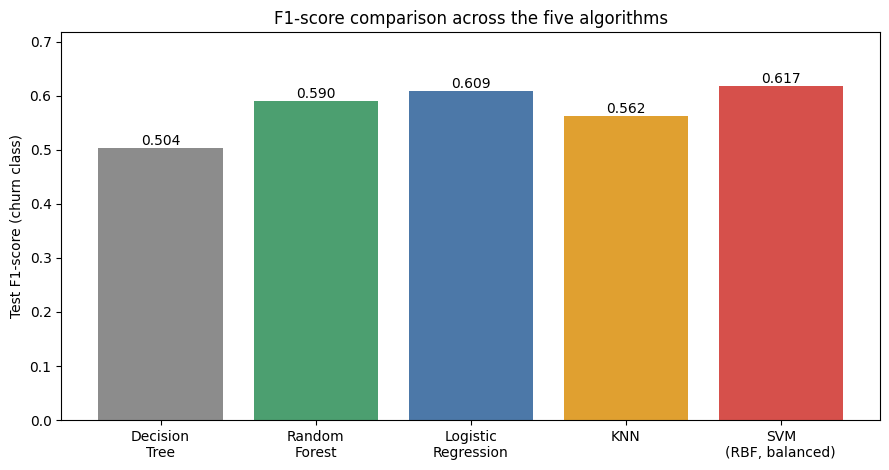

In [19]:
# ONE bar chart: F1-score across the five algorithms (best SVM = the balanced tuned RBF)
five = board.drop(index="SVM - tuned RBF (Part 4)")
names = ["Decision\nTree", "Random\nForest", "Logistic\nRegression", "KNN", "SVM\n(RBF, balanced)"]
fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.bar(names, five["F1-score"].values, color=["#8c8c8c", "#4c9f70", "#4c78a8", "#e0a030", "#d6504b"])
ax.bar_label(bars, fmt="%.3f")
ax.set_ylabel("Test F1-score (churn class)")
ax.set_ylim(0, max(five["F1-score"]) + 0.1)
ax.set_title("F1-score comparison across the five algorithms")
plt.tight_layout()
plt.show()

**Interpretation (F1 bar chart).** The ordering by F1 is balanced SVM (0.617) > Logistic Regression (0.609) > Random Forest (0.590) > KNN (0.562) > Decision Tree (0.504). The top three are within 0.03 of each other, which is small compared with the noise of a 374-churner test set; only the single Decision Tree is clearly behind.

In [20]:
# Supporting evidence for Q6(b) and a fairness check for Q6(c)
# (1) single-fit training time of every final configuration
timing = {}
def timed(name, model, Xa):
    t0 = time.time(); model.fit(Xa, y_train); timing[name] = time.time() - t0
timed("Decision Tree", DecisionTreeClassifier(random_state=42), X_train)
timed("Random Forest", RandomForestClassifier(random_state=42, n_jobs=-1, **rf_gs.best_params_), X_train)
timed("Logistic Regression", LogisticRegression(max_iter=1000, random_state=42), X_train_s)
timed("KNN", KNeighborsClassifier(n_neighbors=knn_gs.best_params_["n_neighbors"]), X_train_s)
timed("SVM RBF (balanced, no probability)", SVC(kernel="rbf", C=bestC, gamma=bestG, class_weight="balanced", random_state=42), X_train_s)
timed("SVM RBF (balanced, probability=True)", SVC(kernel="rbf", C=bestC, gamma=bestG, class_weight="balanced", probability=True, random_state=42), X_train_s)
display(pd.Series(timing, name="Single-fit time (s)").round(2).to_frame())

# (2) fairness check: the SVM got class_weight='balanced', so give LR and RF the same treatment
lr_bal = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42).fit(X_train_s, y_train)
rf_bal = RandomForestClassifier(random_state=42, n_jobs=-1, class_weight="balanced", **rf_gs.best_params_).fit(X_train, y_train)
fair = pd.DataFrame([
    {"Model": "Logistic Regression + balanced", **evaluate(y_test, lr_bal.predict(X_test_s))},
    {"Model": "Random Forest + balanced",       **evaluate(y_test, rf_bal.predict(X_test))},
    {"Model": "SVM RBF + balanced",             **evaluate(y_test, pred_bal)},
]).set_index("Model").round(4)
display(fair)

,Single-fit time (s)
Decision Tree,0.03
Random Forest,1.13
Logistic Regression,0.02
KNN,0.00
"SVM RBF (balanced, no probability)",2.15
"SVM RBF (balanced, probability=True)",8.37


,Accuracy,Precision,Recall,F1-score
Model,,,,
Logistic Regression + balanced,0.7388,0.5052,0.7807,0.6134
Random Forest + balanced,0.7651,0.5410,0.7594,0.6318
SVM RBF + balanced,0.7466,0.5152,0.7701,0.6174


**Interpretation (timing and fairness check).** The SVM was given class weights while LR and RF were left at their defaults, so I gave them the same treatment. LR with balanced weights gets F1 0.6134 / recall 0.7807 and RF with balanced weights gets F1 0.6318 / recall 0.7594 / precision 0.5410 / accuracy 0.7651 — essentially the same as, or slightly better than, the balanced SVM (F1 0.6174, recall 0.7701), at a fraction of the training cost (single-fit times above: tree and logistic regression ≈ 0.02 s, forest ≈ 1 s, balanced SVM ≈ 2 s and ≈ 8 s with `probability=True`).

**Answer 6(a) — Winners.** On the required five-model scoreboard the **balanced RBF-SVM wins both F1 (0.6174) and recall (0.7701)** — it is the same model for both metrics. The winners on the other metrics are different models: Random Forest on precision (0.6701) and Logistic Regression on accuracy (0.8070). The margin on F1 over Logistic Regression is just 0.008.

**Answer 6(b) — Was SVM's extra cost worth it?** Not really. Training is much slower (one fit ≈ 2 s, ≈ 8 s with `probability=True`, and ≈ 80 s for the 125-fit grid search, against ≈ 0.02 s for the tree and logistic regression and ≈ 1 s for the forest), and SVM training time grows at least quadratically with the number of customers. In return the SVM gains only 0.008 F1 over Logistic Regression, and the fairness check shows that Logistic Regression and Random Forest reach equal or better F1 (0.6134 / 0.6318) once they also use balanced class weights. The improvement came from class weighting and not from the SVM's kernel, so the extra computation bought essentially nothing on this dataset.

**Answer 6(c) — Final model.** Within the comparison defined by this lab I select the **balanced tuned RBF-SVM (C = 100, γ = 0.01, `class_weight='balanced'`)** as the final model: it has the best F1 (0.6174) and recall (0.7701) of the five, an ROC-AUC of 0.806 and it finds 288 of the 374 test churners, which is what the business cares about most (Part 5). The price is lower precision (0.5152) and accuracy (0.7466) than Logistic Regression and Random Forest. I want to be explicit about the caveat: the fairness check shows a balanced Random Forest (F1 0.632, accuracy 0.765) or Logistic Regression (F1 0.613) is statistically indistinguishable from, or slightly better than, the SVM and much cheaper; in production I would validate that choice on more data before committing to the more expensive SVM.

---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate `svm_predictions.csv` with the true label, predicted label and predicted churn probability/score for the test set from the final model (the balanced tuned RBF-SVM), and write a short executive summary.

In [21]:
# Task 7.1 - predictions file from the chosen final model (balanced tuned RBF-SVM)
final_model = svm_bal
final_scores = final_model.predict_proba(X_test_s)[:, 1]
final_pred = final_model.predict(X_test_s)

pred_df = pd.DataFrame({
    "true_label": y_test.values,
    "predicted_label": final_pred,
    "churn_probability": final_scores.round(4),
    "decision_function": final_model.decision_function(X_test_s).round(4),
}, index=y_test.index)
pred_df.index.name = "row_index"
pred_df.to_csv("svm_predictions.csv")

print("Saved svm_predictions.csv with", pred_df.shape[0], "rows")
display(pred_df.head(10))
print("Final model test metrics:", {k: round(v, 4) for k, v in evaluate(y_test, final_pred).items()})

Saved svm_predictions.csv with 1409 rows
Final model test metrics: {'Accuracy': 0.7466, 'Precision': 0.5152, 'Recall': 0.7701, 'F1-score': 0.6174}


,true_label,predicted_label,churn_probability,decision_function
row_index,,,,
437,0,0,0.0606,-1.7791
2280,0,1,0.6042,1.2594
2235,0,0,0.0402,-2.1771
4460,0,0,0.2548,-0.1545
3761,0,0,0.0390,-2.2061
5748,0,1,0.6119,1.2887
3568,0,1,0.3621,0.3181
2976,0,0,0.1578,-0.7250
5928,0,0,0.0585,-1.8135


**Executive Summary**

I chose a tuned RBF-kernel SVM (C = 100, γ = 0.01, trained on standardized features with `class_weight='balanced'`) as the final churn model. On the 1,409-customer test set it reaches recall 0.770, precision 0.515, F1 0.617, accuracy 0.747 and ROC-AUC 0.806, catching 288 of 374 churners versus 196 for the same model without class weights. The main trade-off (Part 5) was giving up 7.9 points of precision and 3.9 points of accuracy to gain 24.6 points of recall, which is worthwhile because a missed churner costs more than an unnecessary retention offer (about 1.5 extra offers per extra churner caught). Scaling was essential (un-scaled linear SVM: 0.414 accuracy and a convergence warning versus 0.789 when scaled), while the C × γ search added almost nothing (F1 0.5562 → 0.5568) because the default γ already sits on a broad plateau. One limitation is that all conclusions rest on a single stratified 80/20 split with 374 churners, so differences of 1–3 F1 points between models are within noise; the extra check also showed that balanced Logistic Regression and Random Forest perform as well as the SVM at lower cost, so the SVM's advantage comes from class weighting, not from the kernel.

**Final Reflection**

**(a) Most surprising result.** The most surprising result was how little the careful modelling effort bought compared with one parameter: the 125-fit grid search improved test F1 by 0.0006 and the untuned linear kernel beat RBF and polynomial, whereas simply switching on `class_weight='balanced'` lifted F1 by 0.06 and recall by 25 points. Also striking was the un-scaled SVM, whose accuracy (0.414) was far below the "always predict no churn" baseline (0.735).

**(b) With one more hour.** I would (1) put the scaler and the SVM in a scikit-learn `Pipeline` so cross-validation is leak-free, (2) tune the decision threshold on the precision-recall curve against an assumed cost per retention offer instead of relying on the default boundary, (3) try SMOTE or class-weighted versions of all models with repeated stratified cross-validation, so differences between models can be judged against their variance, (4) engineer features such as number of subscribed services and tenure bands, and (5) extend the grid beyond C = 100 and try a different projection (e.g. LDA) for the margin visualisation.